# SimVQ karşılaştırma raporu

Bu defter, temiz ve bozuk (sentetik olarak bozulmuş) maske ground-truth'larını girdi alıp geçmiş şekil-modeli yöntemlerinin çıktılarıyla SimVQ çıktısını üç eksende karşılaştırır:

1. **Dice skoru** — her yöntemin girdiyi ne kadar sadık yeniden ürettiği (`Dice(girdi, rekonstrüksiyon)`), temiz ve bozuk maskeler için ayrı.
2. **Scatter korelasyon katsayısı** — her yöntemin kalite skoru (QC) ile gerçek Dice arasındaki Spearman ρ. QC sinyali = modelin iyi maske ile bozuk maskeyi ayırt edebilmesi.
3. **Görsel çıktı** — temiz ve farklı bozulma seviyelerindeki örnek maskelerin orta kesitleri, her yöntemin rekonstrüksiyonuyla yan yana.

Karşılaştırılan yöntemler: standart VQ-VAE, commit_scaled, commit_cosine, SimVQ ve DeepSDF (sürekli implicit auto-decoder).

Tüm yöntemler aynı değerlendirme protokolünü kullanır (aynı test bölünmesi, aynı bozulma primitifleri, seed 42), böylece ρ değerleri doğrudan kıyaslanabilir.

In [15]:
import sys, logging
from pathlib import Path

import numpy as np
import torch
%matplotlib inline
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.WARNING)  # değerlendirme makinesinin gürültüsünü kıs

def find_root(start):
    p = Path(start).resolve()
    for c in [p, *p.parents]:
        if (c / 'scripts').is_dir() and (c / 'models').is_dir():
            return c
    return p

PROJECT_ROOT = find_root(Path.cwd())
for p in (PROJECT_ROOT, PROJECT_ROOT / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print('PROJECT_ROOT =', PROJECT_ROOT)

from data import load_config
from models.vae3d_vq import ConvVQVAE3D
from data.sdf_points import SDFPointSampler
from quality.score import correlation
from quality.sdf import TRUNCATION
from train import resolve_device, set_seed

import evaluate_correlation_3d as ev3d
import evaluate_correlation_3d_vq as ev3dvq
import evaluate_correlation_3d_simvq as ev3dsimvq
import evaluate_correlation_3d_deepsdf as ev3ddsdf

device = resolve_device('auto')
print('device =', device)

PROJECT_ROOT = C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality
device = cuda


## 1. Ortak değerlendirme kümesi

Test bölünmesindeki temiz karaciğer maskeleri yüklenir, bozulma aralıkları bu maskeler üzerinde kalibre edilir ve her temiz maskeden `EVAL_N_PER_MASK` adet bozuk varyant üretilir. Sonuç: `masks` (girdiler), `true_dice` (her girdinin temiz haline göre gerçek Dice'ı) ve `is_clean` (temiz mi bayrağı). Tüm yöntemler tam olarak bu kümede skorlanır.

In [11]:
EVAL_N_PER_MASK = 5   # temiz maske başına bozuk varyant sayısı (VQ line ile aynı)
SEED = 42

config = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_vq.yaml'))
config.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)

clean_masks = ev3d.load_clean_volumes(config, 'test', None, SEED)
degrader = ev3d.calibrate_degrader(config, clean_masks, SEED)
masks, true_dice, is_clean = ev3d.build_eval_set(clean_masks, degrader, EVAL_N_PER_MASK, SEED)

is_clean = np.asarray(is_clean, dtype=bool)
deg = ~is_clean
print(f'değerlendirme kümesi: {len(masks)} hacim  ({is_clean.sum()} temiz + {deg.sum()} bozuk)')
print(f'gerçek Dice aralığı: [{true_dice.min():.3f}, {true_dice.max():.3f}]')

değerlendirme kümesi: 282 hacim  (47 temiz + 235 bozuk)
gerçek Dice aralığı: [0.389, 1.000]


## 2. Model kayıt defteri ve yükleyiciler

Her yöntem için checkpoint yolu, yükleyici ve o yöntem için sunulan QC skorunun adı tanımlanır. QC skoru seçimi geçmiş bulgulara dayanır: VQ ailesinde codebook-mesafesi (`quant_error`), SimVQ'da rekonstrüksiyon (`recon_dice`), DeepSDF'te latent atipikliği (`latent_norm`).

In [16]:
CKPT = PROJECT_ROOT / 'outputs' / 'checkpoints'

def load_vq(path):
    """ConvVQVAE3D'yi checkpoint'in kendi vq_mode'uyla yükle."""
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    v = ckpt['config']['vae3d_vq']
    m = ConvVQVAE3D(
        base_channels=int(v['base_channels']), num_embeddings=int(v['num_embeddings']),
        embedding_dim=int(v['embedding_dim']), commitment_cost=float(v['commitment_cost']),
        input_size=tuple(v['input_size']), use_skip=bool(v.get('use_skip', False)),
        vq_mode=str(v.get('vq_mode', 'standard')))
    m.load_state_dict(ckpt['model_state']); m.to(device).eval(); return m

# (etiket, checkpoint, aile, sunulan QC skoru)
REGISTRY = [
    ('standart VQ',   CKPT / 'vae3d_vqvae_best.pt',                'vq',     'quant_error'),
    ('commit_scaled', CKPT / 'vae3d_vqvae_commit_scaled_best.pt',  'vq',     'quant_error'),
    ('commit_cosine', CKPT / 'vae3d_vqvae_commit_cosine_best.pt',  'vq',     'quant_error'),
    ('SimVQ',         CKPT / 'vae3d_simvq_best.pt',                'simvq',  'recon_dice'),
    ('DeepSDF',       CKPT / 'deepsdf_deepsdf_best.pt',            'deepsdf','latent_norm'),
]
for name, path, _, _ in REGISTRY:
    print(('VAR ' if path.exists() else 'YOK ') + name + '  <-  ' + path.name)

VAR standart VQ  <-  vae3d_vqvae_best.pt
VAR commit_scaled  <-  vae3d_vqvae_commit_scaled_best.pt
VAR commit_cosine  <-  vae3d_vqvae_commit_cosine_best.pt
VAR SimVQ  <-  vae3d_simvq_best.pt
VAR DeepSDF  <-  deepsdf_deepsdf_best.pt


## 3. VQ ailesini skorla (standart VQ, commit_scaled, commit_cosine, SimVQ)

Her model için tüm skorlar (`recon_dice`, `quant_error`, ...) ortak kümede hesaplanır. SimVQ'nun `quant_error`'ı efektif codebook `C·W` üzerinden ölçülür (donuk taban C değil). Ayrıca değerlendirme kümesinde kaç ayrık kodun kullanıldığı (codebook doluluğu) sayılır.

In [17]:
@torch.no_grad()
def used_codes(model, masks, effective=False):
    """Değerlendirme kümesinde kullanılan ayrık kod sayısı (codebook doluluğu)."""
    W = model.quantizer.effective_codebook() if effective else model.quantizer.embedding.weight
    used = set()
    for s in range(0, len(masks), 32):
        x = torch.from_numpy(masks[s:s+32].astype('float32'))[:, None].to(device)
        z_e, _ = model._encode_features(x)
        z = z_e.permute(0, 2, 3, 4, 1).reshape(-1, model.embedding_dim)
        d = z.pow(2).sum(1, keepdim=True) - 2 * z @ W.t() + W.pow(2).sum(1)
        used.update(d.argmin(1).cpu().tolist())
    return len(used), W.shape[0]

results = {}  # etiket -> {scores: {name: array}, qc: str, family: str}

for name, path, family, qc in REGISTRY:
    if family == 'deepsdf' or not path.exists():
        continue
    if family == 'simvq':
        model = ev3dsimvq.load_simvq_model(path, device)
        scores = ev3dsimvq.score_masks_simvq(model, masks, device)
        nused, K = used_codes(model, masks, effective=True)
    else:
        model = load_vq(path)
        scores = ev3dvq.score_masks_vq(model, masks, device)
        nused, K = used_codes(model, masks, effective=False)
    results[name] = {'scores': scores, 'qc': qc, 'family': family,
                     'used': nused, 'K': K, 'model': model}
    print(f'{name:14s} | codebook doluluğu {nused:3d}/{K}  ({100*nused/K:4.1f}%)')

standart VQ    | codebook doluluğu  18/512  ( 3.5%)
commit_scaled  | codebook doluluğu   6/512  ( 1.2%)
commit_cosine  | codebook doluluğu 187/512  (36.5%)
SimVQ          | codebook doluluğu 456/512  (89.1%)


## 4. DeepSDF'i skorla (latent çıkarımı)

DeepSDF'in encoder'ı yoktur: her maske, donuk decoder karşısında sıfırdan bir latent `z` optimize edilerek "yeniden üretilir". Bu hücre latent çıkarımı yaptığı için diğerlerinden belirgin şekilde yavaştır (tüm küme, GPU'da birkaç dakika). `latent_norm` (‖z*‖) DeepSDF'in doğal atipiklik ölçüsüdür; `recon_dice` sürekli decoder her şeyi iyi ürettiği için burada kimlik tuzağına düşer.

In [18]:
DEEPSDF_INFER_STEPS = 200   # düşürmek hücreyi hızlandırır (ρ biraz gürültülenir)

deep_entry = next((e for e in REGISTRY if e[2] == 'deepsdf'), None)
if deep_entry and deep_entry[1].exists():
    name, path, _, qc = deep_entry
    dmodel, dcfg = ev3ddsdf.load_deepsdf(path, device)
    dscores = ev3ddsdf.score_masks_deepsdf(
        dmodel, masks, device, dcfg,
        steps=DEEPSDF_INFER_STEPS, lr=0.01, reg=1e-4,
        n_points=2048, near_frac=0.5, batch=16)
    results[name] = {'scores': dscores, 'qc': qc, 'family': 'deepsdf',
                     'used': None, 'K': None, 'model': dmodel, 'dcfg': dcfg}
    print('DeepSDF skorlandı.')
else:
    print('DeepSDF checkpoint yok — atlanıyor.')

c:\Users\ahmet.yaylalioglu\.conda\envs\sam2\Lib\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


KeyboardInterrupt: 

## 5. Özet tablo — Dice skorları ve korelasyon katsayıları

Her yöntem için: değerlendirme kümesindeki codebook doluluğu, temiz ve bozuk maskeler üzerinde ortalama rekonstrüksiyon Dice'ı, sunulan QC skoru ve o skorun gerçek Dice ile Spearman ρ'su, ayrıca karşılaştırma için `recon_dice` ρ'su.

In [ ]:
rows = []
for name, path, family, qc in REGISTRY:
    if name not in results:
        continue
    r = results[name]
    sc = r['scores']
    rd = sc['recon_dice']
    qc_rho = correlation(sc[r['qc']], true_dice)['spearman']
    rd_rho = correlation(rd, true_dice)['spearman']
    dol = '-' if r['used'] is None else f"{r['used']}/{r['K']} ({100*r['used']/r['K']:.0f}%)"
    rows.append({
        'yöntem': name,
        'codebook doluluğu': dol,
        'recon Dice (temiz)': round(float(rd[is_clean].mean()), 3),
        'recon Dice (bozuk)': round(float(rd[deg].mean()), 3),
        'QC skoru': r['qc'],
        'ρ (QC)': round(float(qc_rho), 3),
        'ρ (recon_dice)': round(float(rd_rho), 3),
    })

try:
    import pandas as pd
    summary_df = pd.DataFrame(rows)
    display(summary_df)
except Exception:
    for row in rows:
        print(row)

,yöntem,codebook doluluğu,recon Dice (temiz),recon Dice (bozuk),QC skoru,ρ (QC),ρ (recon_dice)
0,standart VQ,18/512 (4%),0.912,0.825,quant_error,-0.407,0.862
1,commit_scaled,6/512 (1%),0.885,0.793,quant_error,-0.323,0.823
2,commit_cosine,187/512 (37%),0.925,0.856,quant_error,-0.263,0.843
3,SimVQ,456/512 (89%),0.933,0.874,recon_dice,0.843,0.843
4,DeepSDF,-,0.956,0.941,latent_norm,-0.721,0.166


## 6. Scatter korelasyon grafikleri

Her yöntemin sunulan QC skoru, gerçek Dice'a karşı çizilir. Nokta bulutunun eğimi ve dağılımı, skorun kaliteyi ne kadar ayırt ettiğini gösterir; başlıktaki ρ Spearman korelasyonudur. Temiz (Dice=1.0) ve bozuk maskeler ayrı renklendirilir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\simvq_karsilastirma_scatter.png


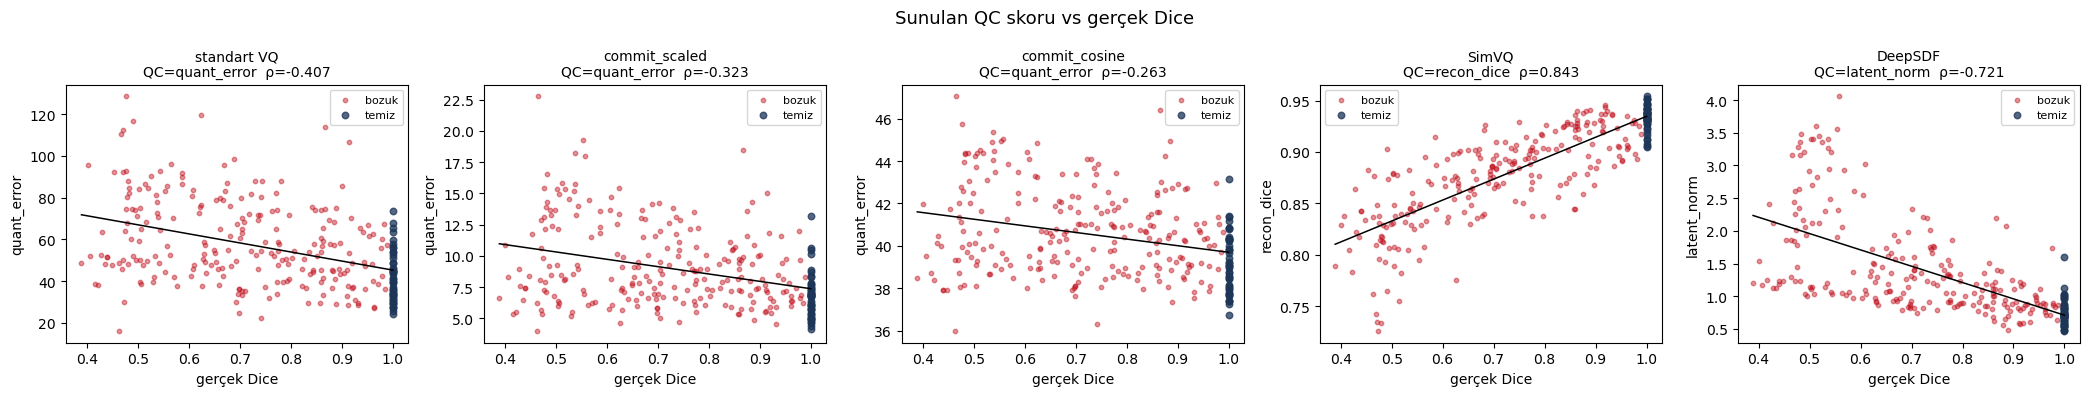

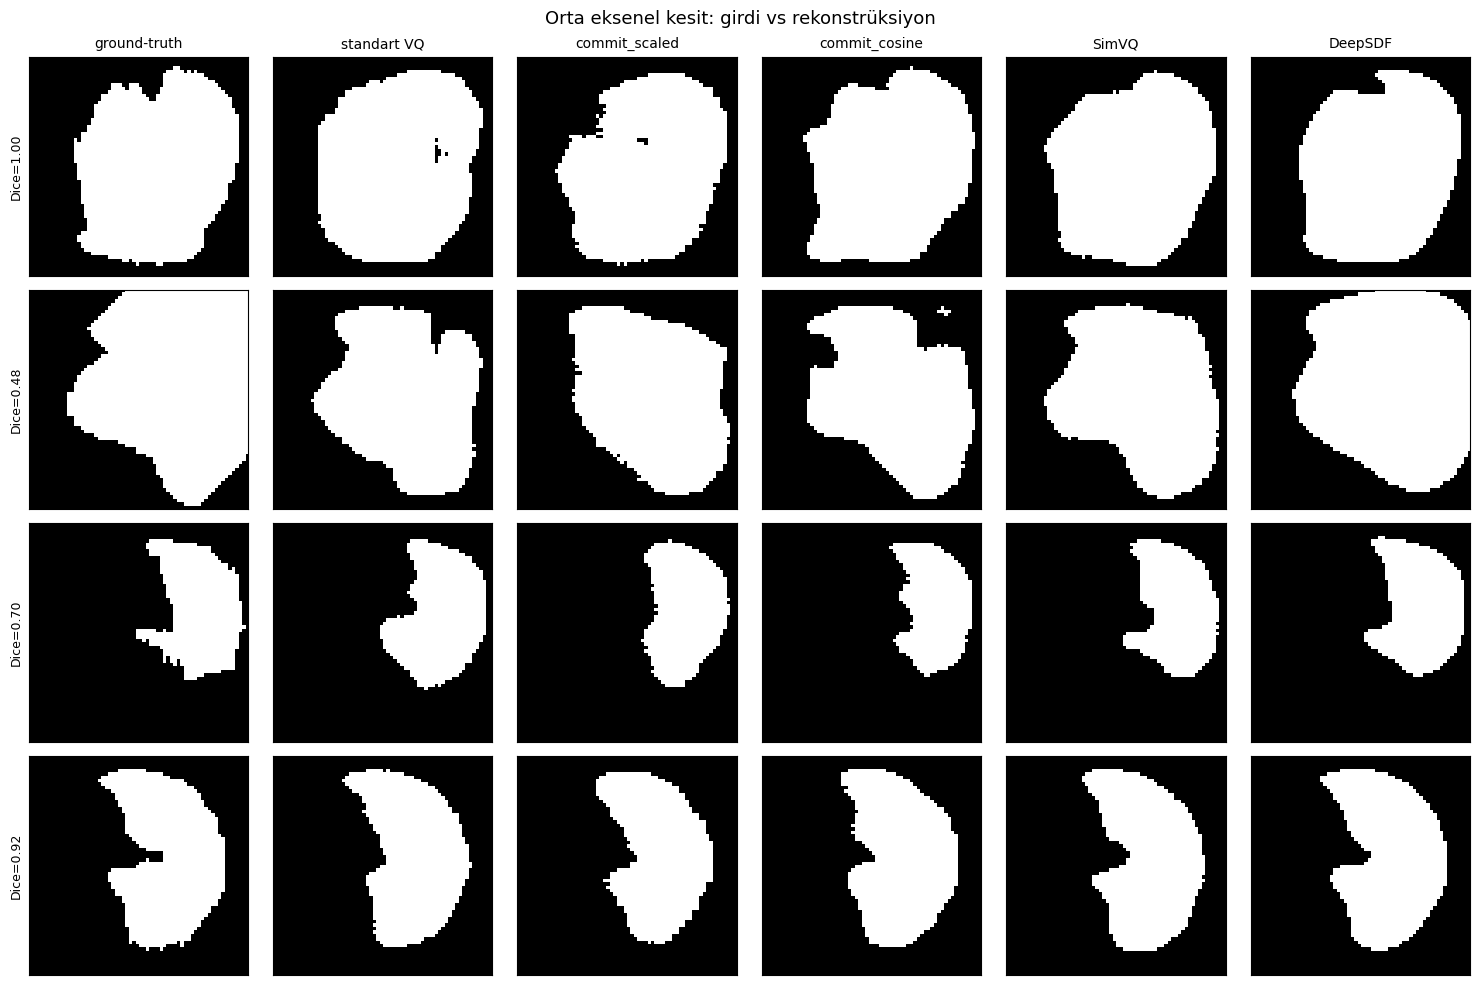

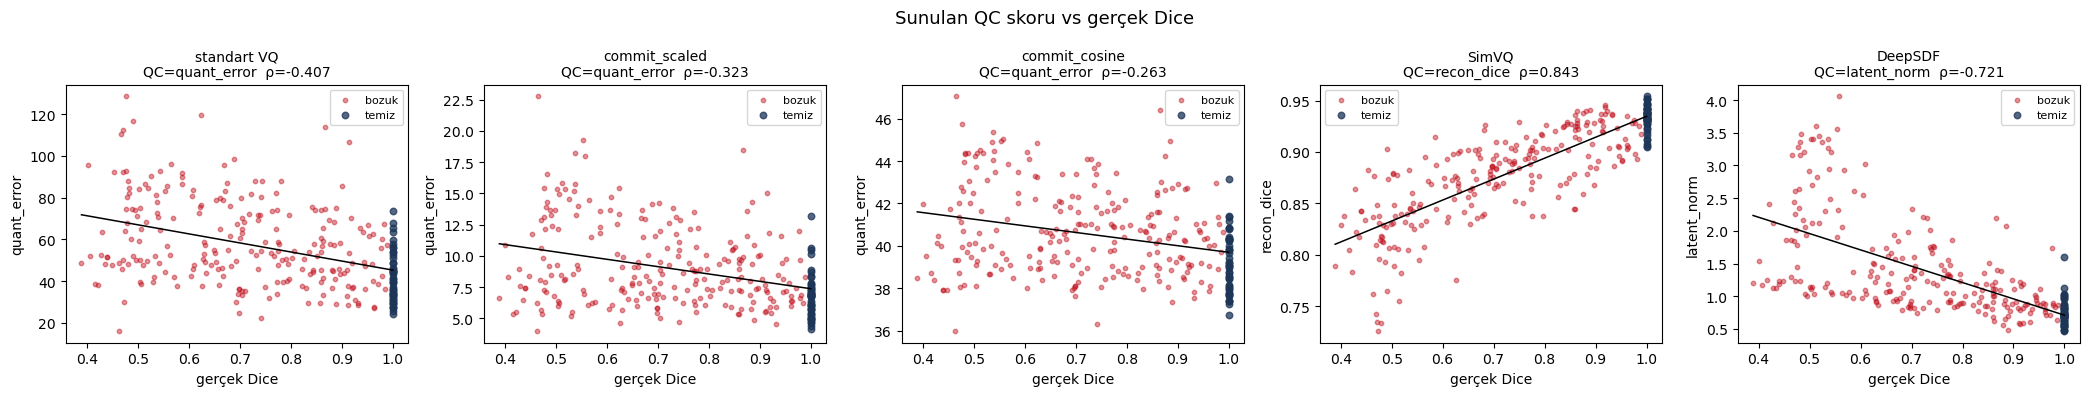

In [12]:
shown = [name for name, *_ in REGISTRY if name in results]
n = len(shown)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.0))
if n == 1:
    axes = [axes]
for ax, name in zip(axes, shown):
    r = results[name]
    s = r['scores'][r['qc']]
    rho = correlation(s, true_dice)['spearman']
    ax.scatter(true_dice[deg], s[deg], s=10, alpha=0.45, c='#c1121f', label='bozuk')
    ax.scatter(true_dice[is_clean], s[is_clean], s=22, alpha=0.75, c='#1d3557', label='temiz')
    order = np.argsort(true_dice)
    coef = np.polyfit(true_dice, s, 1)
    ax.plot(true_dice[order], np.polyval(coef, true_dice[order]), 'k-', lw=1.1)
    ax.set_title(f"{name}\nQC={r['qc']}  ρ={rho:.3f}", fontsize=10)
    ax.set_xlabel('gerçek Dice')
    ax.set_ylabel(r['qc'])
    ax.legend(fontsize=8, loc='best')
fig.suptitle('Sunulan QC skoru vs gerçek Dice', fontsize=13)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'simvq_karsilastirma_scatter.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
print('kaydedildi:', out)
plt.show()

## 7. Görsel rekonstrüksiyonlar

Temiz bir maske ve farklı bozulma seviyelerinden örnekler seçilir; her örneğin orta eksenel kesiti ground-truth ve her yöntemin rekonstrüksiyonu ile yan yana gösterilir. VQ ailesi maskeyi doğrudan `reconstruct` eder; DeepSDF örnek başına latent çıkarımı yapıp SDF alanını ikili maskeye köprüler (`sdf<0`).

In [13]:
@torch.no_grad()
def vq_recon(model, mask):
    x = torch.from_numpy(mask.astype('float32'))[None, None].to(device)
    return (model.reconstruct(x)[0, 0].cpu().numpy() > 0.5)

def deepsdf_recon(model, dcfg, mask_list, chunk=65536):
    trunc = float(dcfg.get('truncation', TRUNCATION))
    sampler = SDFPointSampler([m.astype('float32') for m in mask_list],
                              truncation=trunc, surface_band=float(dcfg['surface_band']))
    idx = list(range(len(mask_list)))
    z = ev3ddsdf.infer_latents(model, sampler, idx, device, steps=DEEPSDF_INFER_STEPS,
                               lr=0.01, reg=1e-4, n_points=2048, near_frac=0.5,
                               latent_dim=int(dcfg['latent_dim']), truncation=trunc)
    coords = sampler.coords.to(device)
    vols = []
    with torch.no_grad():
        for row in idx:
            preds = []
            zc = z[row:row+1]
            for st in range(0, coords.shape[0], chunk):
                c = coords[st:st+chunk]
                preds.append(model.decode(zc.expand(c.shape[0], -1), c))
            sdf = torch.cat(preds).clamp(-trunc, trunc).reshape(sampler.shape)
            vols.append((sdf < 0).cpu().numpy())
    return vols

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\simvq_karsilastirma_gorseller.png


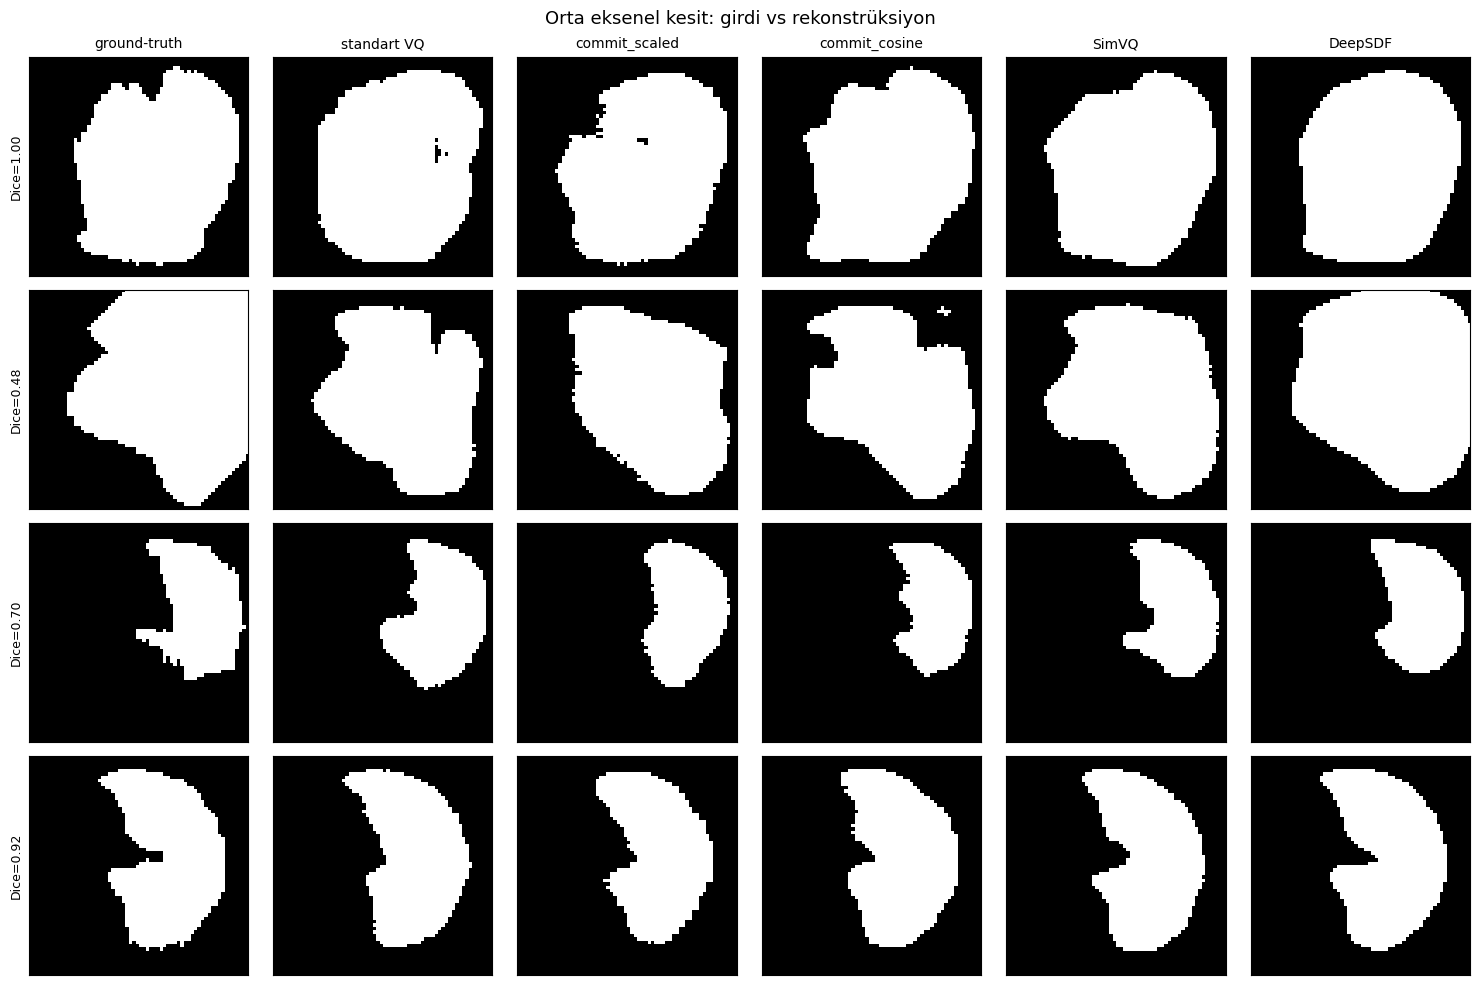

In [14]:
# örnek seç: 1 temiz + bozukların düşük/orta/yüksek Dice çeyrekleri
clean_idx = int(np.where(is_clean)[0][0])
deg_ids = np.where(deg)[0]
deg_sorted = deg_ids[np.argsort(true_dice[deg_ids])]
picks = [clean_idx] + [int(deg_sorted[int(q * (len(deg_sorted) - 1))]) for q in (0.1, 0.5, 0.9)]
sel_masks = [masks[i].astype('float32') for i in picks]
sel_dice = [true_dice[i] for i in picks]

# DeepSDF rekonstrüksiyonlarını sadece seçilen örnekler için üret (ucuz)
deep_vols = None
if 'DeepSDF' in results:
    deep_vols = deepsdf_recon(results['DeepSDF']['model'], results['DeepSDF']['dcfg'], sel_masks)

cols = ['ground-truth'] + shown
fig, axes = plt.subplots(len(picks), len(cols), figsize=(2.5 * len(cols), 2.5 * len(picks)))
axes = np.atleast_2d(axes)
for r, (mi, td) in enumerate(zip(picks, sel_dice)):
    mask = masks[mi]
    zc = mask.shape[0] // 2  # orta eksenel kesit
    axes[r, 0].imshow(mask[zc], cmap='gray'); axes[r, 0].set_ylabel(f'Dice={td:.2f}', fontsize=9)
    axes[r, 0].set_title('ground-truth' if r == 0 else '', fontsize=10)
    for c, name in enumerate(shown, start=1):
        fam = results[name]['family']
        if fam == 'deepsdf':
            rec = deep_vols[picks.index(mi)] if deep_vols is not None else np.zeros_like(mask)
        else:
            rec = vq_recon(results[name]['model'], mask)
        axes[r, c].imshow(rec[zc], cmap='gray')
        if r == 0:
            axes[r, c].set_title(name, fontsize=10)
    for c in range(len(cols)):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
fig.suptitle('Orta eksenel kesit: girdi vs rekonstrüksiyon', fontsize=13)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'simvq_karsilastirma_gorseller.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
print('kaydedildi:', out)
plt.show()

## 8. Bulguların özeti

- **SimVQ codebook çöküşünü giderir:** tek paylaşılan lineer katman `W` ile efektif codebook `C·W` bütün olarak hareket eder; değerlendirme kümesinde doluluk vanilla VQ'nun düştüğü birkaç koddan onlarca koda çıkar. Rekonstrüksiyon Dice'ı VQ ile rekabetçidir.
- **Çöküşü gidermek codebook-mesafesi QC'sini zayıflatır:** codebook dolduğunda her maskeye (bozuk dahil) yakın bir kod bulunduğu için `quant_error` iyi/kötü ayrımını kaybeder. Bu, `commit_cosine` (yüksek doluluk → zayıf QC) ile aynı örüntüdür.
- **SimVQ için sunulan QC sinyali `recon_dice`'tır:** ayrık darboğaz rekonstrüksiyon Dice'ını dürüst tutar (DeepSDF'teki kimlik tuzağının aksine), dolayısıyla girdi-rekonstrüksiyon farkı kaliteyi ayırt eder.
- **DeepSDF'te `recon_dice` kimlik tuzağına düşer, `latent_norm` ayakta kalır:** sürekli decoder bozuk maskeyi de iyi üretir; atipiklik latent normunda yakalanır.

Üretilen dosyalar: `outputs/simvq_karsilastirma_scatter.png`, `outputs/simvq_karsilastirma_gorseller.png`.